# 06. Timely detection and the exact adversarial loop

This notebook covers **phase 7**. A detection only helps if the response arrives before the intruder reaches
the target (EASI model, Garcia 2007). It then builds the loop "the optimiser places the sensors, the intruder
finds the flaw, the optimiser corrects" in a form that **converges and certifies** its result. Formulation and
proofs: `docs/formulation.md` §9.

In [10]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. Remaining time and minimal intrusion time

Let $t_e = \ell_e / v + t_\times(e)$ be the time to walk an edge, plus the climbing or gate time if it crosses
the fence. The minimal time from a cell $v$ to the target is

$$
d(v) = \min_{\gamma : v \to \text{target}} \sum_{e \in \gamma} t_e ,
$$

one multi-source Dijkstra from the targets, per profile. It **does not depend on the sensors**. A detection at
$v$ is **timely** for a response time $T_R$ if $d(v) \ge T_R$. The minimal intrusion time is
$T_\text{min} = \min_{s \in \text{starts}} d(s)$.

{'F': 'T_min = 50.0 s', 'G': 'T_min = 50.0 s'}


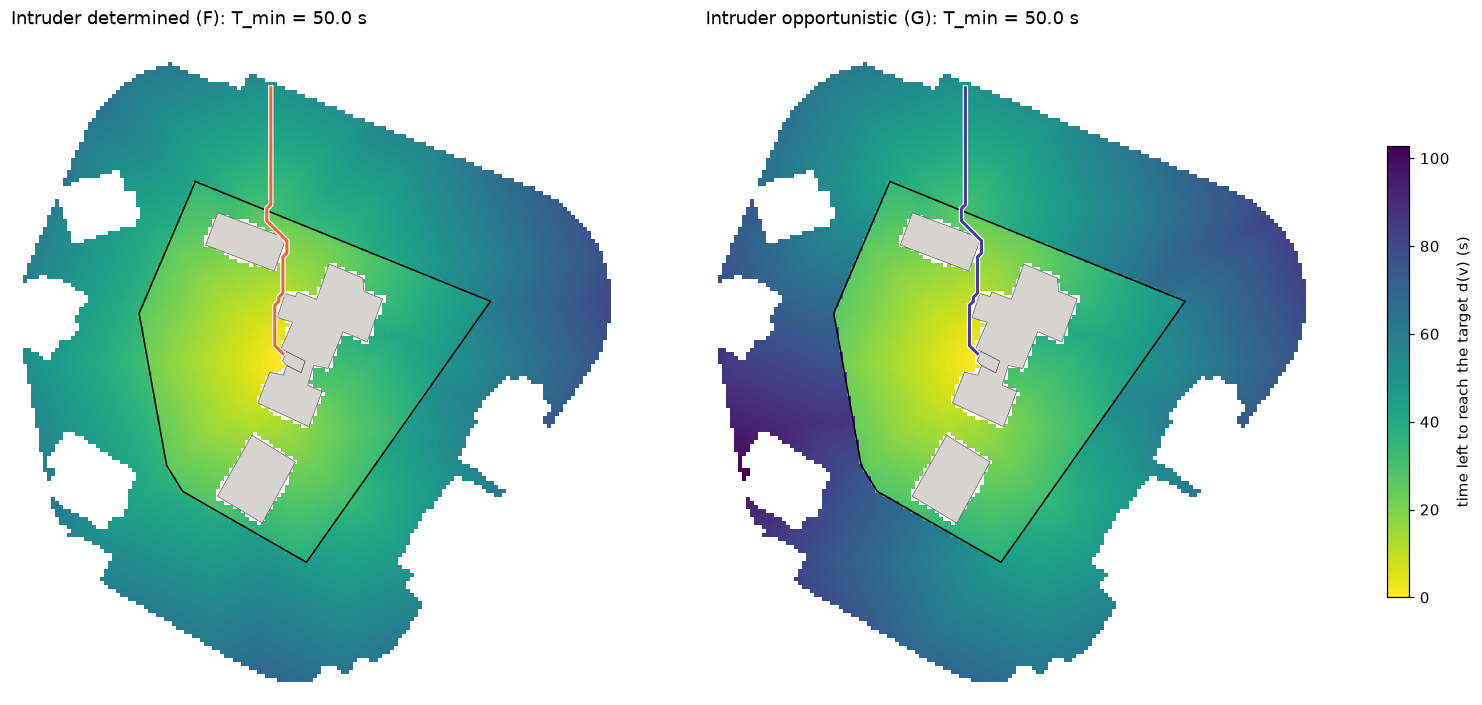

In [11]:
import geopandas as gpd

from src.intruder import PROFILES, load_domain
from src.rasters import load_grid
from src.timely import fastest_path, time_remaining

ic = cfg["intruder"]
dom, A, conf = load_domain(cfg, ROOT)
grid = load_grid(Path(cfg["site"]["grid_yaml"]))
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter").geometry.iloc[0]
assets = gpd.read_file(cfg["site"]["output_gpkg"], layer="assets")
d = {pr: time_remaining(dom, ic, pr) for pr in PROFILES}
T_min = {pr: float(d[pr][dom.source].min()) for pr in PROFILES}
print({pr: f"T_min = {T_min[pr]:.1f} s" for pr in PROFILES})

r, c = dom.rows, dom.cols
X = grid.xmin + (c + 0.5) * grid.res
Y = grid.ymax - (r + 0.5) * grid.res
r0, r1, c0, c1 = r.min() - 3, r.max() + 4, c.min() - 3, c.max() + 4
ext = (grid.xmin + c0, grid.xmin + c1, grid.ymax - r1, grid.ymax - r0)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.3), layout="constrained")
vmax = max(np.nanmax(np.where(np.isfinite(d[p]), d[p], np.nan)) for p in PROFILES)
for ax, pr, col in zip(axes, PROFILES, ("#eb6834", "#4a3aa7")):
    img = np.full((grid.height, grid.width), np.nan)
    img[r, c] = np.where(np.isfinite(d[pr]), d[pr], np.nan)
    im = ax.imshow(img[r0:r1, c0:c1], extent=ext, cmap="viridis_r", vmin=0, vmax=vmax)
    gpd.GeoSeries(list(assets.geometry)).plot(ax=ax, color="#d6d4cf", edgecolor="#52514e", lw=0.4)
    ax.plot(*per.exterior.xy, color="k", lw=1)
    p = fastest_path(dom, ic, pr)
    ax.plot(X[p], Y[p], color="white", lw=3.5); ax.plot(X[p], Y[p], color=col, lw=2)
    name = "determined (F)" if pr == "F" else "opportunistic (G)"
    ax.set_title(f"Intruder {name}: T_min = {T_min[pr]:.1f} s", loc="left"); ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.7, label="time left to reach the target d(v) (s)")
plt.show()

## 2. The guaranteed timely detection $\tilde p^\star$

Masking the detections that come too late, $\tilde P_v = P_v \cdot \mathbb{1}[d(v) \ge T_R]$, and applying the
corridor threshold of notebook 05 gives $\tilde p^\star = p^\star(\tilde P)$, a proven **lower bound** of the
guaranteed timely detection (along a real path, the time left at $u$ is at least $d(u)$).

**Proposition 2.** If $T_R > T_\text{min}$, then $\tilde p^\star = 0$ **for every layout**: along the fastest
path, every node has $d \le T_\text{min} < T_R$. Beyond $T_\text{min}$, only delay (fence, gates) or earlier
detection can help; sensors cannot. Checked below with **every** configuration of the catalog switched on
(the ceiling of any layout):

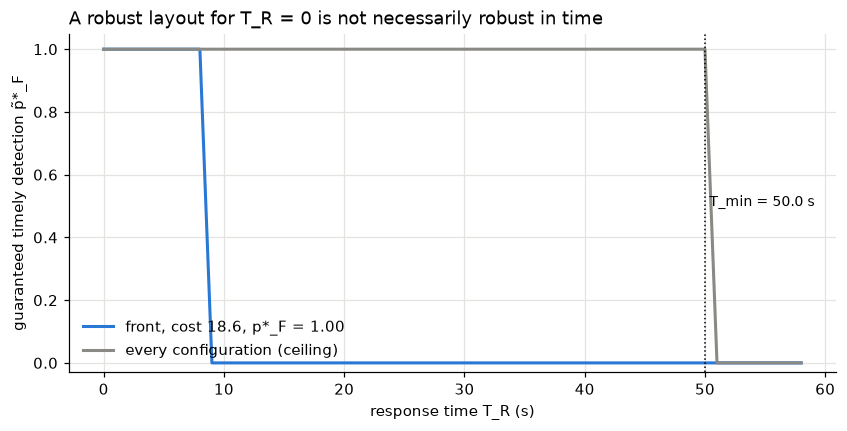

In [12]:
from src.intruder import corridor_threshold, detection
from src.timely import ceiling, evaluate_timely

front = pd.read_csv(Path(cfg["nsga"]["out_dir"]) / "front_global.csv")
best = front.sort_values(["p_star_F", "cost"], ascending=[False, True]).iloc[0]   # most robust point
T_best = np.array(str(best.configs).split(), np.int64)
cases = {f"front, cost {best.cost:.1f}, p*_F = {best.p_star_F:.2f}": detection(A, T_best),
         "every configuration (ceiling)": ceiling(A)}
grid_TR = np.arange(0, np.ceil(T_min["F"]) + 8, 1.0)
fig, ax = plt.subplots(figsize=(9, 4))
for (name, (P, sigma)), col in zip(cases.items(), ("#2a78d6", "#8a8984")):
    pt = [evaluate_timely(dom, P, sigma, ic, float(t), d)["p_tilde_F"] for t in grid_TR]
    ax.plot(grid_TR, pt, color=col, lw=2, label=name)
ax.axvline(T_min["F"], color="k", ls=":", lw=1)
ax.annotate(f" T_min = {T_min['F']:.1f} s", (T_min["F"], 0.5), fontsize=9)
ax.set_xlabel("response time T_R (s)"); ax.set_ylabel("guaranteed timely detection p̃*_F")
ax.set_ylim(-0.03, 1.05); ax.legend(frameon=False, loc="lower left")
ax.set_title("A robust layout for T_R = 0 is not necessarily robust in time", loc="left")
plt.show()

## 3. Linearising the requirement

With $s_{vj} = -\ln(1 - P_{vj})$ and $s_\theta = -\ln(1 - \theta)$, under independence,

$$
P_v(x) \ge \theta \iff \sum_j s_{vj} x_j \ge s_\theta \iff \sum_j C_{vj} x_j \ge 1,
\qquad C_{vj} = \min(s_{vj} / s_\theta, 1).
$$

The truncation at 1 is exact (if a term reaches 1, both sides hold). Under the pessimistic **max fusion**
(fully correlated detections, $P_v = \max_j P_{vj}$), $C_{vj} = \mathbb{1}[P_{vj} \ge \theta]$ and the problem
becomes a pure set cover. A check on random data:

In [13]:
from scipy import sparse

from src.adversarial_loop import coefficients, level

rng = np.random.default_rng(3)
D = rng.random((6, 40)) * (rng.random((6, 40)) < 0.6)
Asmall = sparse.csr_matrix(D)
ok = []
for fusion in ("product", "max"):
    for theta in (0.3, 0.6, 0.9):
        C = coefficients(Asmall, theta, fusion)
        for _ in range(20):
            T = np.flatnonzero(rng.random(6) < 0.5)
            P = detection(Asmall, T)[0] if fusion == "product" else (D[T].max(axis=0) if T.size else 0 * D[0])
            ok.append(((level(C, T) >= 1 - 1e-9) == (P >= theta - 1e-9)).all())
print(f"equivalence holds in {sum(ok)}/{len(ok)} random draws")

equivalence holds in 120/120 random draws


## 4. The loop as constraint generation

$\tilde p^\star(x) \ge \theta$ if and only if **every** path from a start to the target contains a node $v$ with
$d(v) \ge T_R$ and $P_v(x) \ge \theta$. With binary $z_v \le \sum_j C_{vj} x_j$, each path $\gamma$ gives a cut
$\sum_{v \in \gamma,\ d(v) \ge T_R} z_v \ge 1$. Paths are exponentially many, so they are generated on demand:

| Role | Content |
|---|---|
| **Master** (MILP, HiGHS) | minimal cost under (C2)-(C4) and the cuts of the corridors found so far |
| **Intruder** (oracle) | the union-find of notebook 05 on the master's layout; returns open corridors, each one a new cut |
| **Stop** | the intruder finds no corridor, and the master proves nothing cheaper exists |

The master is a relaxation, so its bound is valid at every iteration, and the loop terminates (finitely many
paths). A naive loop that only penalises the last corridor found can oscillate; this one certifies. Exact
speed-ups (an aggregated cut in $x$, a shared pool of corridors, a cutoff by the incumbent, the removal of
dominated configurations) make it practical. On a toy site, compared with an exhaustive enumeration of the
$2^7$ layouts:

In [14]:
import itertools

from src.adversarial_loop import adversarial_loop
from src.instance import Instance, cost, violations
from src.intruder import Domain
from src.intruder_domain import build_edges
from src.site import Grid

IC = dict(speed_m_s=1.5, t_fence_s=10.0, t_gate_s=3.0, tau_obs_s=1.0)
H, W = 7, 8
g0 = Grid(crs="EPSG:2950", xmin=0.0, ymin=0.0, xmax=W, ymax=H, res=1.0)
rows0, cols0 = np.nonzero(np.ones((H, W), bool))
inside0 = cols0 >= 4                                     # fence between columns 3 and 4
u, v, l, fr = build_edges(g0, rows0, cols0, inside0)
ext0 = np.where(~inside0[u], u, v)
gate0 = np.where(fr & (rows0[ext0] == 3), 0, -1).astype(np.int16)   # a gate on row 3
toy = Domain(rows=rows0, cols=cols0, inside=inside0, source=cols0 == 0, target=cols0 == W - 1,
             u=u, v=v, length=l, crosses=fr, gate=gate0)
nJ = 7
theta, T_R = 0.6, 3.0


def toy_instance(seed):
    rng = np.random.default_rng(seed)
    D = rng.random((nJ, toy.n)) * (rng.random((nJ, toy.n)) < 0.45)
    D[D > 0.85] = 1.0
    inst = Instance(A=sparse.csr_matrix(D[:, toy.inside]), w=np.ones(toy.inside.sum()),
                    support=rng.integers(0, 4, nJ), kind=rng.integers(0, 2, nJ),
                    cost_sensor=np.round(rng.uniform(0.5, 2, nJ), 2), site=np.array([0, 0, 1, 1]),
                    cost_support=np.round(rng.uniform(0.2, 1, 4), 2), capacity=np.array([2, 1]))
    return sparse.csr_matrix(D), inst


def enumerate_min_cost(A0, inst0, d0):
    best = np.inf
    for k in range(nJ + 1):
        for T in itertools.combinations(range(nJ), k):
            T = np.array(T, np.int64)
            if violations(inst0, T, 1e6):
                continue
            P = detection(A0, T)[0]
            if corridor_threshold(toy, np.where(d0 >= T_R, P, 0.0), "F")[0] >= theta - 1e-9:
                best = min(best, cost(inst0, T))
    return best


d0 = time_remaining(toy, IC, "F")
for seed in range(50):                        # first random instance where a feasible layout exists
    A0, inst0 = toy_instance(seed)
    best = enumerate_min_cost(A0, inst0, d0)
    if np.isfinite(best):
        break
res = adversarial_loop(inst0, toy, A0, d0, theta, T_R, "F", "cost", n_paths=3, fusion="product")
print(f"loop: {res.status}, cost {res.value:.2f}, {res.iterations} iterations, {res.n_cuts} cuts | "
      f"exhaustive enumeration: {best:.2f}")
res.history[["iteration", "bound", "best", "n_cuts_x", "n_cuts_z", "feasible"]]

loop: optimal, cost 4.64, 6 iterations, 11 cuts | exhaustive enumeration: 4.64


,iteration,bound,best,n_cuts_x,n_cuts_z,feasible
0,1,1.61,inf,5,0,False
1,2,3.15,inf,6,0,False
2,3,3.20,inf,8,1,False
3,4,3.44,inf,10,1,False
4,5,4.64,4.64,10,1,True
5,6,4.64,4.64,10,1,True


## 5. On the site

The certified minimal cost $c(\theta, T_R)$ for the determined intruder, max fusion, as computed by
`python -m src.adversarial_loop cost` (here $\theta \in \{0.5, 0.9\}$, $T_R \in \{0, 10\}$ s).
`cost_front` is the cheapest point of the NSGA-II front that meets the same requirement, evaluated under
**independent** detections; the certified optimum uses the pessimistic **max fusion**, so the front can be
cheaper when several partial sensors combine (θ = 0.9, $T_R$ = 0 below), and much more expensive when it
never optimised the timing ($T_R$ = 10 s):

In [15]:
rc = pd.read_csv(Path(cfg["loop"]["out_dir"]) / "robust_cost.csv")
rc[["theta", "T_R", "status_max", "cost_max", "cost_front", "iterations", "time_max_s", "n_radar",
    "n_camera", "F"]].round(3)

,theta,T_R,status_max,cost_max,cost_front,iterations,time_max_s,n_radar,n_camera,F
0,0.50,0.0,optimal,2.2,2.2,1,2.341,0,1,0.180
1,0.50,10.0,optimal,6.6,6.6,2,3.119,1,0,0.507
2,0.50,20.0,optimal,9.8,18.6,6,21.040,1,2,0.390
3,0.50,30.0,optimal,12.4,21.2,8,50.426,2,0,0.393
4,0.90,0.0,optimal,5.8,4.2,9,21.192,0,3,0.224
5,0.90,10.0,optimal,6.8,12.4,3,3.353,1,0,0.502
6,0.90,20.0,optimal,11.3,19.8,9,38.116,1,3,0.387
7,0.90,30.0,optimal,12.6,21.2,2,3.953,2,0,0.662
8,0.95,0.0,optimal,5.8,6.0,2,10.761,0,3,0.249
9,0.95,10.0,optimal,7.0,12.4,2,3.714,1,0,0.471


One case solved live, with the loop printing its bound and its best solution at each iteration. The result is
then **checked independently**: $\tilde p^\star$ is recomputed from the detection matrix, without the
coefficients $C$ used by the master.

In [16]:
from src.adversarial_loop import front_nsga, load, p_tilde

dom_, A_, conf_, inst, cells, d_ = load(cfg, ROOT)
theta, T_R = 0.9, 10.0
r_ = adversarial_loop(inst, dom_, A_, d_["F"], theta, T_R, "F", "cost", seeds=front_nsga(ROOT, cfg),
                      n_paths=cfg["loop"]["paths_per_iteration"], max_time_s=300,
                      master_time_s=cfg["loop"]["master_time_s"], fusion="max", verbose=True)
check = p_tilde(dom_, A_, r_.T, d_["F"], T_R, "F")
print(f"\n{r_.status}: cost {r_.value:.2f}, independent check p̃* = {check:.3f} ≥ θ = {theta}")
conf_.iloc[r_.T][["cand", "support", "h", "sensor", "azimuth", "tilt"]]

    it   1 |    2.9 s | bound 6.6000 | best 12.4000 | cuts x 50, z 0 (0 z)
    it   2 |    3.1 s | bound 6.8000 | best 12.4000 | cuts x 51, z 0 (0 z)
    it   3 |    3.3 s | bound 6.8000 | best 6.8000 | cuts x 51, z 0 (0 z)

optimal: cost 6.80, independent check p̃* = 0.921 ≥ θ = 0.9


,cand,support,h,sensor,azimuth,tilt
1278,C011,fence_mast,8.0,radar_perimeter,NaN,15.0


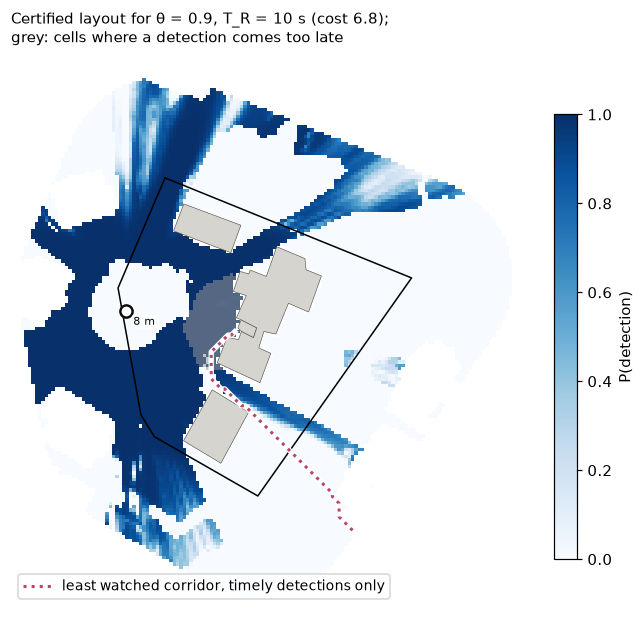

In [17]:
from src.analysis import draw_sensors

P, _ = detection(A_, r_.T)
_, corr_timely = corridor_threshold(dom_, np.where(d_["F"] >= T_R, P, 0.0), "F")
cand = gpd.read_file(cfg["candidates"]["output"]).set_index("id")
cand["x"], cand["y"] = cand.geometry.x, cand.geometry.y
hfov = {c_["name"]: c_["hfov_deg"] for c_ in cfg["sensors"]["cameras"]}

img = np.full((grid.height, grid.width), np.nan); img[r, c] = P
late = np.full((grid.height, grid.width), np.nan); late[r[d_["F"] < T_R], c[d_["F"] < T_R]] = 1
fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(img[r0:r1, c0:c1], extent=ext, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.imshow(late[r0:r1, c0:c1], extent=ext, cmap="Greys", vmin=0, vmax=2, alpha=0.55,
          interpolation="nearest")
gpd.GeoSeries(list(assets.geometry)).plot(ax=ax, color="#d6d4cf", edgecolor="#52514e", lw=0.4)
ax.plot(*per.exterior.xy, color="k", lw=1)
ax.plot(X[corr_timely], Y[corr_timely], color="white", lw=3.5)
ax.plot(X[corr_timely], Y[corr_timely], color="#b8456a", lw=2, ls=":",
        label="least watched corridor, timely detections only")
draw_sensors(ax, r_.T, conf_, cand, hfov, r_wedge=10)
fig.colorbar(im, ax=ax, shrink=0.75, label="P(detection)")
ax.legend(frameon=True, loc="lower left", fontsize=9); ax.set_axis_off()
ax.set_title(f"Certified layout for θ = {theta:g}, T_R = {T_R:g} s (cost {r_.value:.1f});\n"
             "grey: cells where a detection comes too late", loc="left", fontsize=10)
plt.show()

Detecting early means **looking outside**: the certified layout watches the approach, where the coverage
weight is zero, because a detection at the foot of the target comes too late.

## 6. Delay: the lever that sensors do not replace

$T_\text{min}$ grows with the crossing times. Reinforcing the fence alone is capped by the gates, which the
determined intruder then uses:

In [18]:
rows_ = []
for tc, tp in ((10, 3), (30, 3), (30, 30), (60, 60), (120, 120)):
    ic_s = dict(ic, t_fence_s=float(tc), t_gate_s=float(tp))
    rows_.append({"fence climb t_c (s)": tc, "gate passage t_p (s)": tp,
                  "T_min (s)": round(float(time_remaining(dom, ic_s, "F")[dom.source].min()), 1)})
pd.DataFrame(rows_)

,fence climb t_c (s),gate passage t_p (s),T_min (s)
0,10,3,50.0
1,30,3,50.0
2,30,30,71.2
3,60,60,101.2
4,120,120,161.2


The sensitivity analysis (`python -m src.sensitivity`) measures, under a preregistered protocol, what each wrong
assumption (summer foliage, a running intruder, the band width) would cost to repair.

This closes the chain. The last notebook, [07. The surrogate model](07_surrogate_model.ipynb), goes back to
the visibility computation and asks where deep learning actually helps.